In [1]:
import numpy as np

y_actual = np.array([100, 150, 200, 250])

initial_prediction = np.mean(y_actual)

residuals = y_actual - initial_prediction

print("Initial prediction:", initial_prediction)
print("Residuals:", residuals)

Initial prediction: 175.0
Residuals: [-75. -25.  25.  75.]


In [2]:
learning_rate = 0.1

tree_corrections = residuals

updated_predictions = (
    initial_prediction
    + learning_rate * tree_corrections
)

print(updated_predictions)

[167.5 172.5 177.5 182.5]


## SCRATCH

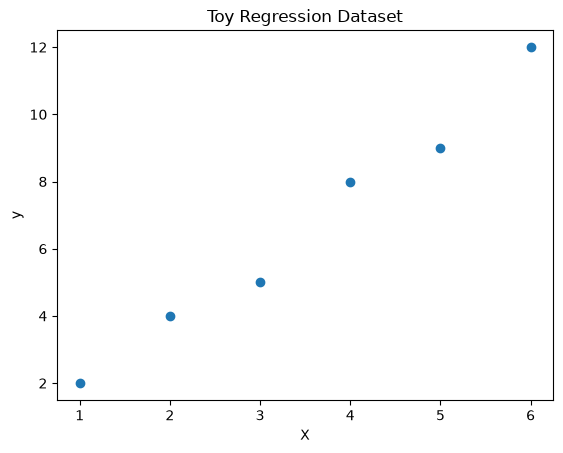

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

X = np.array([1, 2, 3, 4, 5, 6], dtype=float).reshape(-1, 1)
y = np.array([2, 4, 5, 8, 9, 12], dtype=float)

plt.scatter(X, y)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Toy Regression Dataset")
plt.show()

In [4]:
initial_prediction = np.mean(y)

learning_rate = 0.1
n_estimators = 3

predictions = np.full(
    shape=len(y),
    fill_value=initial_prediction,
    dtype=float
)

print("Initial prediction:", initial_prediction)
print("Initial predictions:", predictions)

Initial prediction: 6.666666666666667
Initial predictions: [6.66666667 6.66666667 6.66666667 6.66666667 6.66666667 6.66666667]


In [5]:
trees = []

for iteration in range(n_estimators):
    residuals = y - predictions

    tree = DecisionTreeRegressor(
        max_depth=1,
        random_state=42
    )

    tree.fit(X, residuals)

    correction = tree.predict(X)

    predictions += learning_rate * correction

    trees.append(tree)

    mse = np.mean((y - predictions) ** 2)

    print(f"Tree {iteration + 1}")
    print("Residuals:", residuals)
    print("Corrections:", correction)
    print("Updated predictions:", predictions)
    print("MSE:", mse)
    print()

Tree 1
Residuals: [-4.66666667 -2.66666667 -1.66666667  1.33333333  2.33333333  5.33333333]
Corrections: [-3. -3. -3.  3.  3.  3.]
Updated predictions: [6.36666667 6.36666667 6.36666667 6.96666667 6.96666667 6.96666667]
MSE: 9.512222222222222

Tree 2
Residuals: [-4.36666667 -2.36666667 -1.36666667  1.03333333  2.03333333  5.03333333]
Corrections: [-2.7 -2.7 -2.7  2.7  2.7  2.7]
Updated predictions: [6.09666667 6.09666667 6.09666667 7.23666667 7.23666667 7.23666667]
MSE: 8.127122222222223

Tree 3
Residuals: [-4.09666667 -2.09666667 -1.09666667  0.76333333  1.76333333  4.76333333]
Corrections: [-2.43 -2.43 -2.43  2.43  2.43  2.43]
Updated predictions: [5.85366667 5.85366667 5.85366667 7.47966667 7.47966667 7.47966667]
MSE: 7.00519122222222



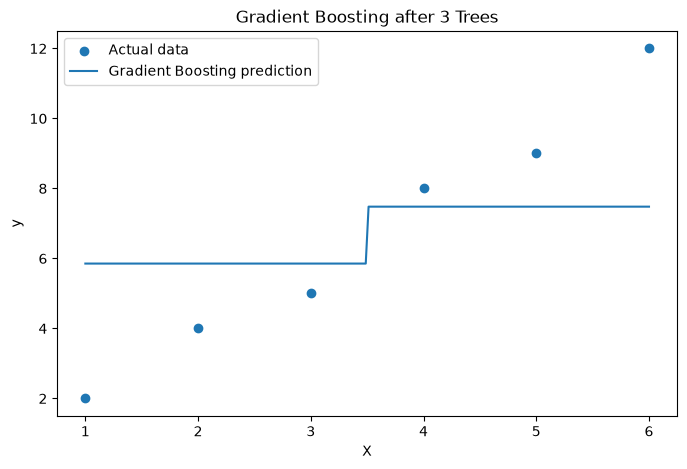

In [6]:
X_plot = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

plot_predictions = np.full(
    len(X_plot),
    initial_prediction,
    dtype=float
)

for tree in trees:
    plot_predictions += learning_rate * tree.predict(X_plot)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Actual data")
plt.plot(X_plot, plot_predictions, label="Gradient Boosting prediction")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Gradient Boosting after 3 Trees")
plt.legend()
plt.show()

## ADD MORE BOOSTING TREES

In [7]:
n_estimators = 100

predictions = np.full(
    len(y),
    initial_prediction,
    dtype=float
)

trees = []
mse_history = []

for iteration in range(n_estimators):
    residuals = y - predictions

    tree = DecisionTreeRegressor(
        max_depth=1,
        random_state=42
    )

    tree.fit(X, residuals)

    correction = tree.predict(X)
    predictions += learning_rate * correction

    trees.append(tree)

    mse = np.mean((y - predictions) ** 2)
    mse_history.append(mse)

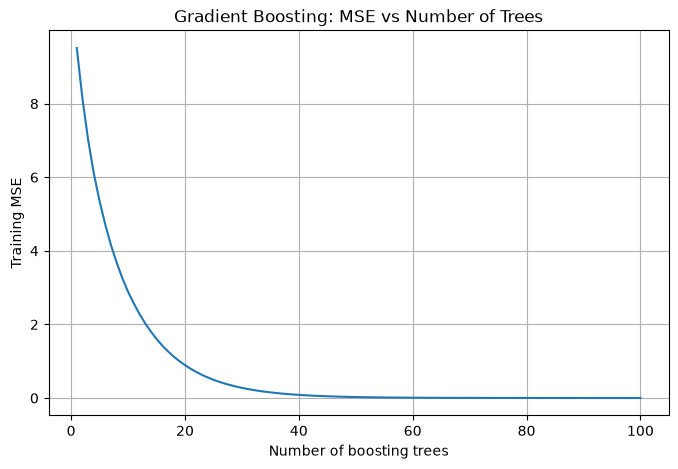

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, n_estimators + 1),
    mse_history
)

plt.xlabel("Number of boosting trees")
plt.ylabel("Training MSE")
plt.title("Gradient Boosting: MSE vs Number of Trees")
plt.grid(True)
plt.show()

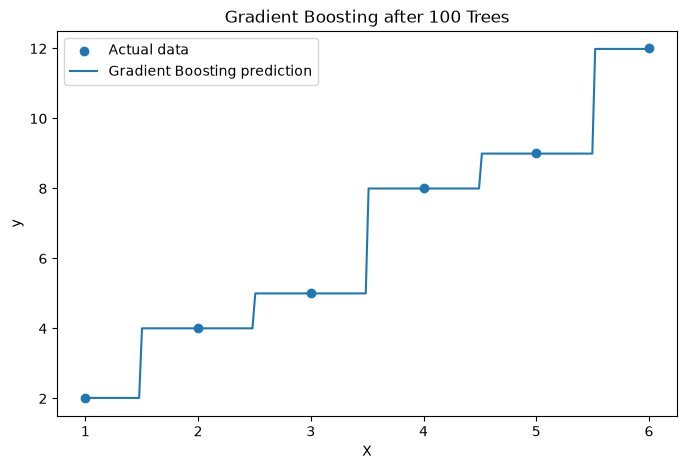

In [9]:
X_plot = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

plot_predictions = np.full(
    len(X_plot),
    initial_prediction,
    dtype=float
)

for tree in trees:
    plot_predictions += learning_rate * tree.predict(X_plot)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Actual data")
plt.plot(X_plot, plot_predictions, label="Gradient Boosting prediction")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Gradient Boosting after 100 Trees")
plt.legend()
plt.show()

In [11]:
import pandas as pd

learning_rates = [0.01, 0.1, 0.5, 1.0]
tree_counts = [10, 50, 100]

lr_results = []

for lr in learning_rates:
    for n_trees in tree_counts:
        current_predictions = np.full(
            len(y),
            np.mean(y),
            dtype=float
        )

        for _ in range(n_trees):
            residuals = y - current_predictions

            tree = DecisionTreeRegressor(
                max_depth=1,
                random_state=42
            )

            tree.fit(X, residuals)

            current_predictions += lr * tree.predict(X)

        mse = np.mean((y - current_predictions) ** 2)

        lr_results.append({
            "learning_rate": lr,
            "n_estimators": n_trees,
            "training_mse": mse
        })

pd.DataFrame(lr_results)

,learning_rate,n_estimators,training_mse
0,0.01,10,9.583385e+00
1,0.01,50,5.505441e+00
2,0.01,100,3.049340e+00
3,0.10,10,2.889320e+00
4,0.10,50,2.622272e-02
5,0.10,100,7.337911e-05
6,0.50,10,1.626886e-02
7,0.50,50,3.340742e-05
8,0.50,100,1.421423e-08
9,1.00,10,6.285711e-02


## SCIKIT-LEARN

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()

X = data.data
y = data.target

feature_names = data.feature_names
target_names = data.target_names

# Keep the same train/test split used in previous experiments
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Classes:", target_names)

X_train: (455, 30)
X_test: (114, 30)
Classes: ['malignant' 'benign']


In [14]:
X_train_gb, X_val_gb, y_train_gb, y_val_gb = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_gb.shape)
print("Validation:", X_val_gb.shape)

Training: (364, 30)
Validation: (91, 30)


In [15]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=1,
    random_state=42
)

gb_model.fit(X_train_gb, y_train_gb)

val_predictions = gb_model.predict(X_val_gb)

print("Validation accuracy:", accuracy_score(y_val_gb, val_predictions))
print(classification_report(y_val_gb, val_predictions))

Validation accuracy: 0.967032967032967
              precision    recall  f1-score   support

           0       0.97      0.94      0.96        34
           1       0.97      0.98      0.97        57

    accuracy                           0.97        91
   macro avg       0.97      0.96      0.96        91
weighted avg       0.97      0.97      0.97        91



In [16]:
train_predictions = gb_model.predict(X_train_gb)
val_predictions = gb_model.predict(X_val_gb)

print(
    "Training accuracy:",
    accuracy_score(y_train_gb, train_predictions)
)

print(
    "Validation accuracy:",
    accuracy_score(y_val_gb, val_predictions)
)

Training accuracy: 0.9917582417582418
Validation accuracy: 0.967032967032967


In [17]:
from sklearn.metrics import accuracy_score

train_acc_by_stage = []
val_acc_by_stage = []

for train_pred, val_pred in zip(
    gb_model.staged_predict(X_train_gb),
    gb_model.staged_predict(X_val_gb)
):
    train_acc_by_stage.append(
        accuracy_score(y_train_gb, train_pred)
    )

    val_acc_by_stage.append(
        accuracy_score(y_val_gb, val_pred)
    )

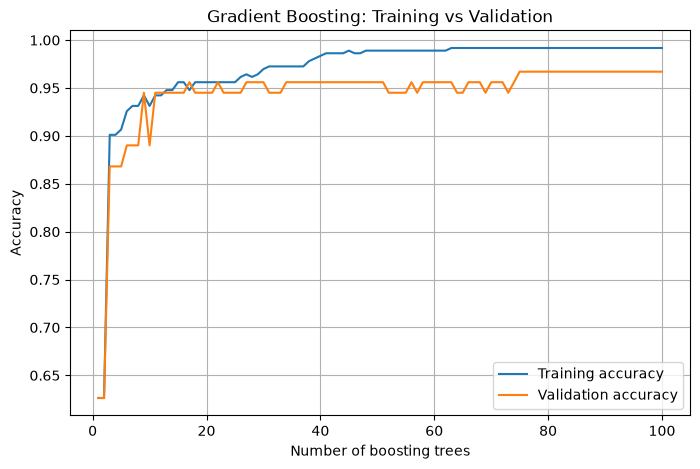

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_acc_by_stage) + 1),
    train_acc_by_stage,
    label="Training accuracy"
)

plt.plot(
    range(1, len(val_acc_by_stage) + 1),
    val_acc_by_stage,
    label="Validation accuracy"
)

plt.xlabel("Number of boosting trees")
plt.ylabel("Accuracy")
plt.title("Gradient Boosting: Training vs Validation")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
best_stage = np.argmax(val_acc_by_stage) + 1
best_val_accuracy = max(val_acc_by_stage)

print("Best number of trees:", best_stage)
print("Best validation accuracy:", best_val_accuracy)

Best number of trees: 75
Best validation accuracy: 0.967032967032967


In [20]:
gb_final = GradientBoostingClassifier(
    n_estimators=75,
    learning_rate=0.1,
    max_depth=1,
    random_state=42
)

gb_final.fit(X_train_gb, y_train_gb)

val_predictions_final = gb_final.predict(X_val_gb)

print(
    "Validation accuracy:",
    accuracy_score(y_val_gb, val_predictions_final)
)

Validation accuracy: 0.967032967032967


In [21]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

test_predictions_gb = gb_final.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, test_predictions_gb))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions_gb))

print("\nClassification report:")
print(classification_report(y_test, test_predictions_gb))

Test accuracy: 0.9385964912280702

Confusion matrix:
[[38  4]
 [ 3 69]]

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        42
           1       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114

